In [1]:
import pandas as pd

In [2]:
df = pd.read_excel(r"C:\Users\ARIO\Downloads\online+retail (1)\Online Retail.xlsx")

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
df = df.dropna(subset=['CustomerID'])
df.shape

(406829, 8)

In [12]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [13]:
df.shape

(397924, 8)

In [14]:
df = df[df['Quantity'] > 0]

In [15]:
df.shape

(397924, 8)

In [17]:
df = df[df['UnitPrice'] > 0]
df.shape

(397884, 8)

In [18]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [21]:
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [22]:
df.shape

(397884, 9)

In [23]:
print(df['InvoiceDate'].min())
print(df['InvoiceDate'].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


In [24]:
import datetime as dt
reference_date = dt.datetime(2011, 12, 10)

In [25]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

In [28]:
rfm.shape


(4338, 3)

In [27]:
rfm.head()

,InvoiceDate,InvoiceNo,TotalPrice
CustomerID,,,
12346.0,325,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,18,1,1757.55
12350.0,310,1,334.40


In [29]:
rfm.columns = ['Recency', 'Frequency', 'Monetary']

In [30]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,18,1,1757.55
12350.0,310,1,334.40


In [31]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.059474,4.272015,2054.266460
std,100.012264,7.697998,8989.230441
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,307.415000
50%,50.000000,2.000000,674.485000
75%,141.750000,5.000000,1661.740000
max,373.000000,209.000000,280206.020000


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

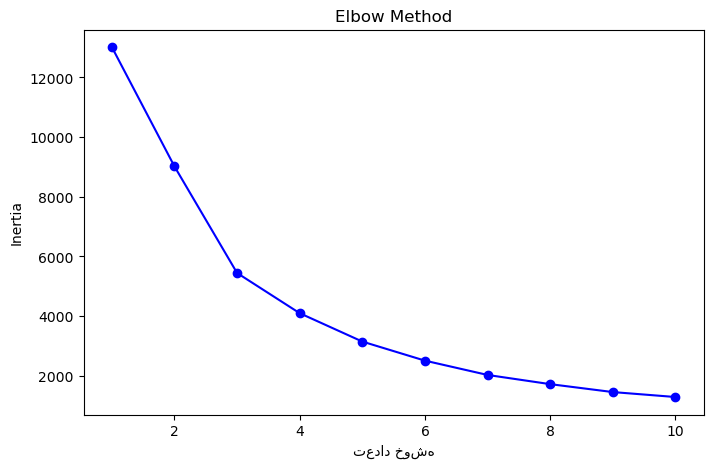

In [33]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, 'bo-')
plt.xlabel('تعداد خوشه')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

تعداد خوشه = 1 → Inertia = 13014.00
تعداد خوشه = 2 → Inertia = 9012.60
تعداد خوشه = 3 → Inertia = 5439.65
تعداد خوشه = 4 → Inertia = 4092.42
تعداد خوشه = 5 → Inertia = 3141.36
تعداد خوشه = 6 → Inertia = 2502.22
تعداد خوشه = 7 → Inertia = 2022.72
تعداد خوشه = 8 → Inertia = 1714.69
تعداد خوشه = 9 → Inertia = 1449.14
تعداد خوشه = 10 → Inertia = 1283.37


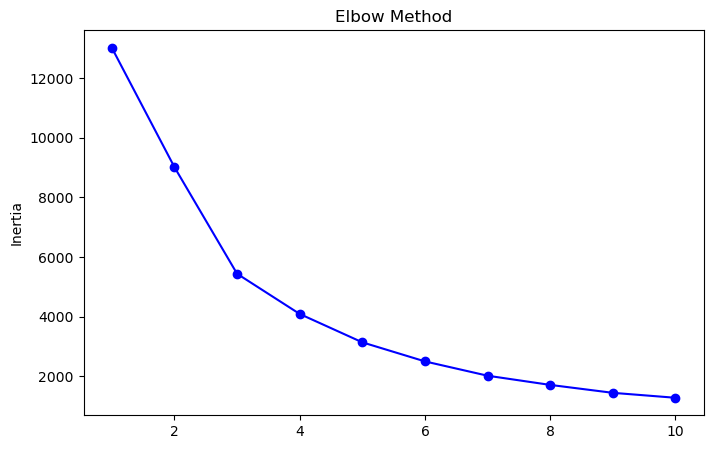

In [37]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)
    print(f"تعداد خوشه = {k} → Inertia = {kmeans.inertia_:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, 'bo-')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [38]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

In [39]:
rfm['Cluster'].value_counts().sort_index()

Cluster
0    3060
1    1061
2      13
3     204
Name: count, dtype: int64

In [43]:
from sklearn.model_selection import train_test_split
target = 'WHITE HANGING HEART T-LIGHT HOLDER'
buyers = df[df['Description'] == target]['CustomerID'].unique()
rfm['Class'] = rfm.index.isin(buyers).astype(int)
print(rfm['Class'].value_counts())

X = rfm[['Recency', 'Frequency', 'Monetary', 'Cluster']]
y = rfm['Class']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


Class
0    3482
1     856
Name: count, dtype: int64


Accuracy: 0.804147465437788
[[693   4]
 [166   5]]


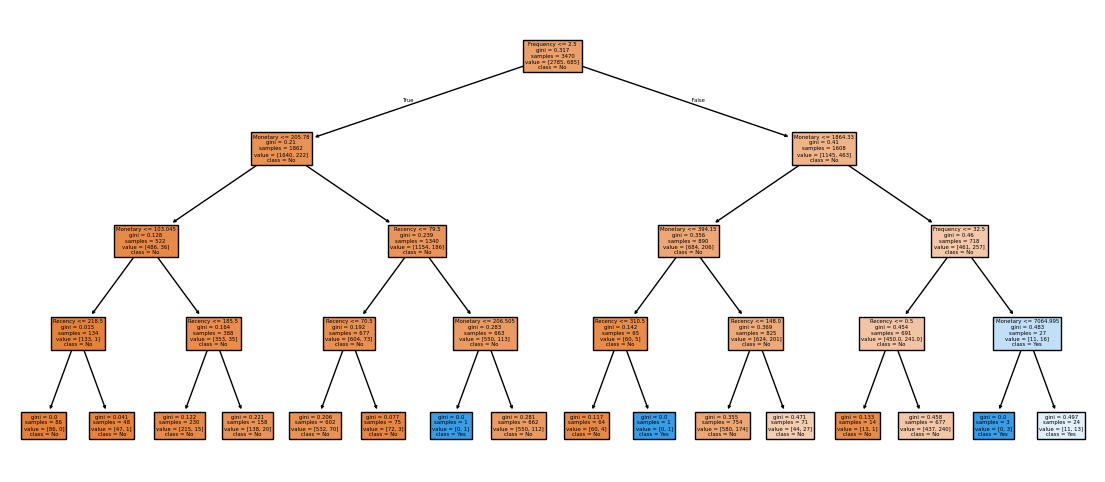

In [44]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix




model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


plt.figure(figsize=(14, 6))
plot_tree(model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.show()